# Predict ordered class probabilities

Ordered categories have a meaningful ranking without a numeric distance between levels. We simulate a latent logistic response separated by thresholds, fit an ordered GAM, and inspect all three class probabilities.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from nampy.gam import GAM
from nampy.models import GAMLSS

rng=np.random.default_rng(108)
data=pd.DataFrame({"x":rng.uniform(0,1,700)})
grid=pd.DataFrame({"x":np.linspace(0,1,180)})
from scipy.special import expit
eta=1.6*np.sin(2*np.pi*data.x)
latent=eta+rng.logistic(size=len(data))
data["y"]=np.digitize(latent,[-1.,1.])+1
train,test=train_test_split(data,test_size=.25,stratify=data.y,random_state=108)
model=GAM(formula="y ~ s(x,bs='cr',k=12)",family={"name":"ocat","R":3},optimize_smoothing=True,smoothing_method="reml").fit(train)
probability=np.asarray(model.predict(grid,type="response"))
eta_grid=1.6*np.sin(2*np.pi*grid.x)
cumulative=np.column_stack([expit(-1-eta_grid),expit(1-eta_grid)])
known=np.column_stack([cumulative[:,0],cumulative[:,1]-cumulative[:,0],1-cumulative[:,1]])
assert probability.shape==(len(grid),3)
np.testing.assert_allclose(probability.sum(axis=1),1.,atol=1e-8)

## Compare probabilities and test outcomes

Probability columns follow the ordered classes 1, 2, and 3. We assess the complete probability vector with log loss, rather than treating the class labels as continuous measurements.

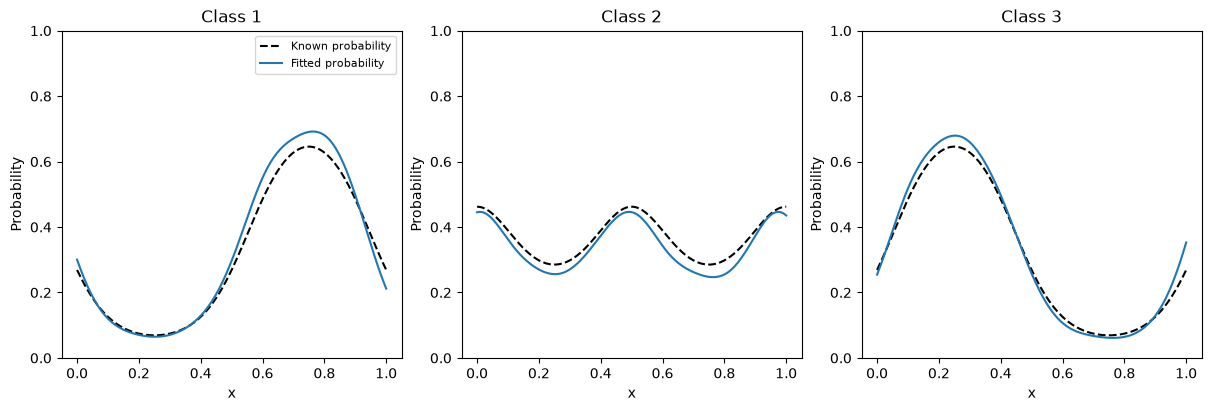

Test log loss
1.030


In [2]:
figure,axes=plt.subplots(1,3,figsize=(12,4),constrained_layout=True)
for column,axis in enumerate(axes):
    axis.plot(grid.x,known[:,column],"k--",label="Known probability")
    axis.plot(grid.x,probability[:,column],label="Fitted probability")
    axis.set(title=f"Class {column+1}",xlabel="x",ylabel="Probability",ylim=(0,1))
axes[0].legend(fontsize=8)
plt.show()
plt.close(figure)
from sklearn.metrics import log_loss
p_test=np.asarray(model.predict(test,type="response"))
pd.DataFrame({"Test log loss":[log_loss(test.y,p_test,labels=[1,2,3])]}).style.hide(axis="index").format("{:.3f}")